# Week 2 — Exploratory Data Analysis

This notebook analyzes the **Store Sales - Time Series Forecasting** data to understand sales trends, seasonality, and relationships with stores, families, promotions, holidays, transactions, and oil prices.

All numbers and figures below are produced from the real dataset in `data/raw/`; nothing is fabricated. If the data is missing, the notebook prints download instructions and skips data-dependent cells.

**Scope:** descriptive analysis only. No model is trained here.

## 1. Setup

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from retail_sales_forecasting.analysis import (
    daily_sales,
    holidays_by_type,
    merge_oil_with_sales,
    missing_value_report,
    monthly_sales_trend,
    oil_price_trend,
    promotion_summary,
    sales_by_family,
    sales_by_month,
    sales_by_store,
    sales_by_weekday,
    yearly_sales_trend,
)
from retail_sales_forecasting.config import FIGURES_DIR
from retail_sales_forecasting.data_loader import (
    available_datasets,
    load_available_datasets,
)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name):
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved figure: {path}")

print(f"Figures directory: {FIGURES_DIR}")

Figures directory: D:\code\retail-sales-forecasting-main\reports\figures


In [2]:
if "train" in available_datasets():
    datasets = load_available_datasets()
    train = datasets["train"]
    stores = datasets["stores"]
    oil = datasets["oil"]
    holidays = datasets["holidays_events"]
    transactions = datasets["transactions"]
    print("Loaded datasets:", ", ".join(datasets))
    print(f"train.csv: {train.shape[0]:,} rows x {train.shape[1]} columns")
else:
    datasets = {}
    train = stores = oil = holidays = transactions = None
    print(
        "train.csv is not available. Download from "
        "https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data "
        "into data/raw/, then re-run this notebook."
    )

Loaded datasets: train, test, stores, oil, holidays_events, transactions
train.csv: 3,000,888 rows x 6 columns


## 2. Overall sales trend

Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_sales_trend.png


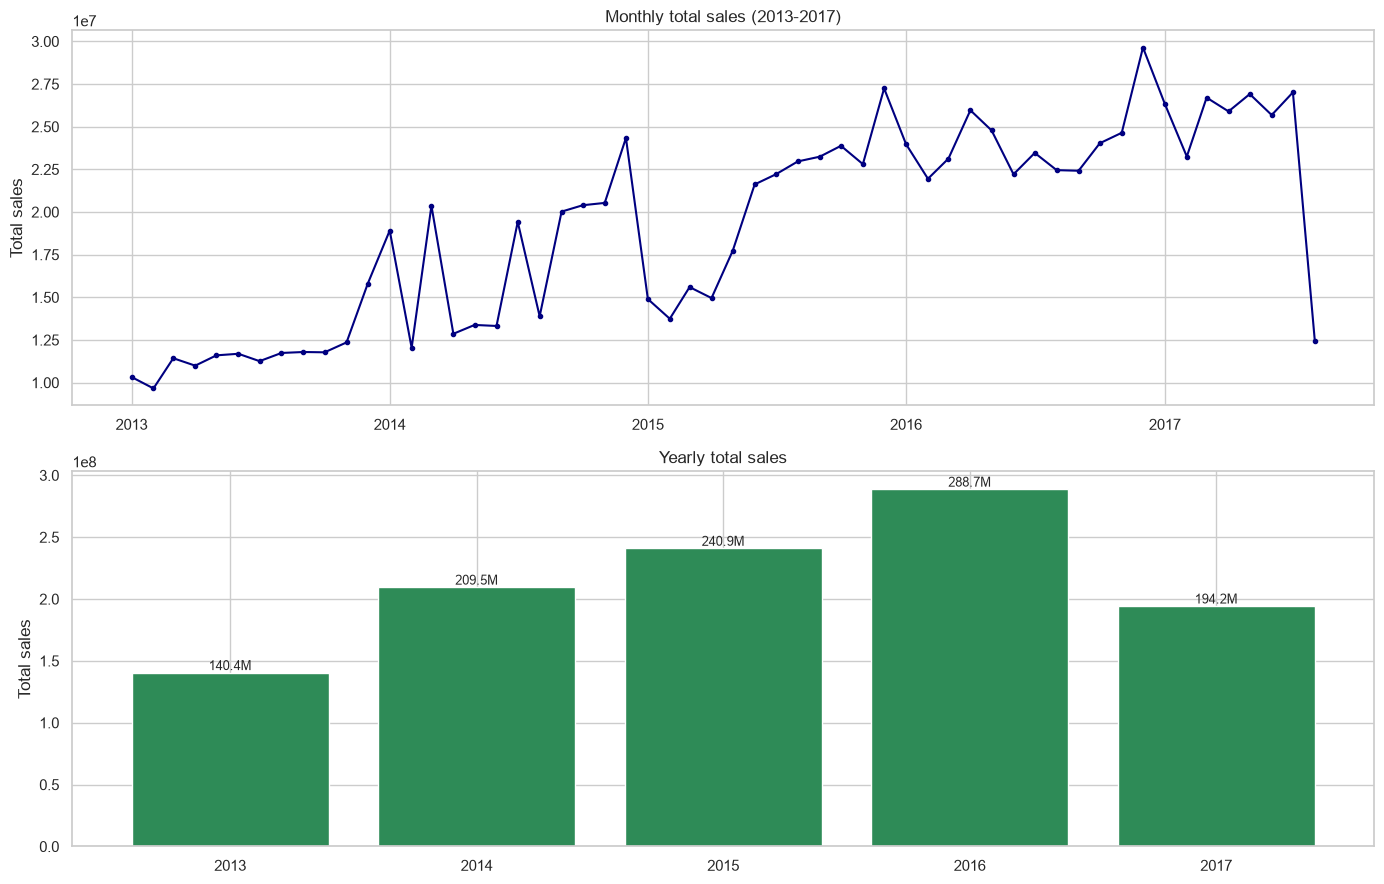

First month: 2013-01-01 10,327,625
Last full month: 2017-07-01 27,011,478


In [3]:
if train is not None:
    monthly = monthly_sales_trend(train)
    yearly = yearly_sales_trend(train)

    fig, axes = plt.subplots(2, 1, figsize=(14, 9))
    axes[0].plot(monthly["month"], monthly["sales"], marker="o", ms=3, color="navy")
    axes[0].set_title("Monthly total sales (2013-2017)")
    axes[0].set_ylabel("Total sales")

    axes[1].bar(yearly["year"].astype(str), yearly["sales"], color="seagreen")
    axes[1].set_title("Yearly total sales")
    axes[1].set_ylabel("Total sales")
    for i, value in enumerate(yearly["sales"]):
        axes[1].text(i, value, f"{value/1e6:.1f}M", ha="center", va="bottom", fontsize=9)

    fig.tight_layout()
    save_figure(fig, "week2_sales_trend.png")
    plt.show()

    print("First month:", monthly.iloc[0]["month"].date(), f"{monthly.iloc[0]['sales']:,.0f}")
    print("Last full month:", monthly.iloc[-2]["month"].date(), f"{monthly.iloc[-2]['sales']:,.0f}")
else:
    print("Skipped: training data is not loaded.")

## 3. Weekly and monthly seasonality

Mean of total daily sales for each day of week and each calendar month across the full period.

Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_seasonality.png


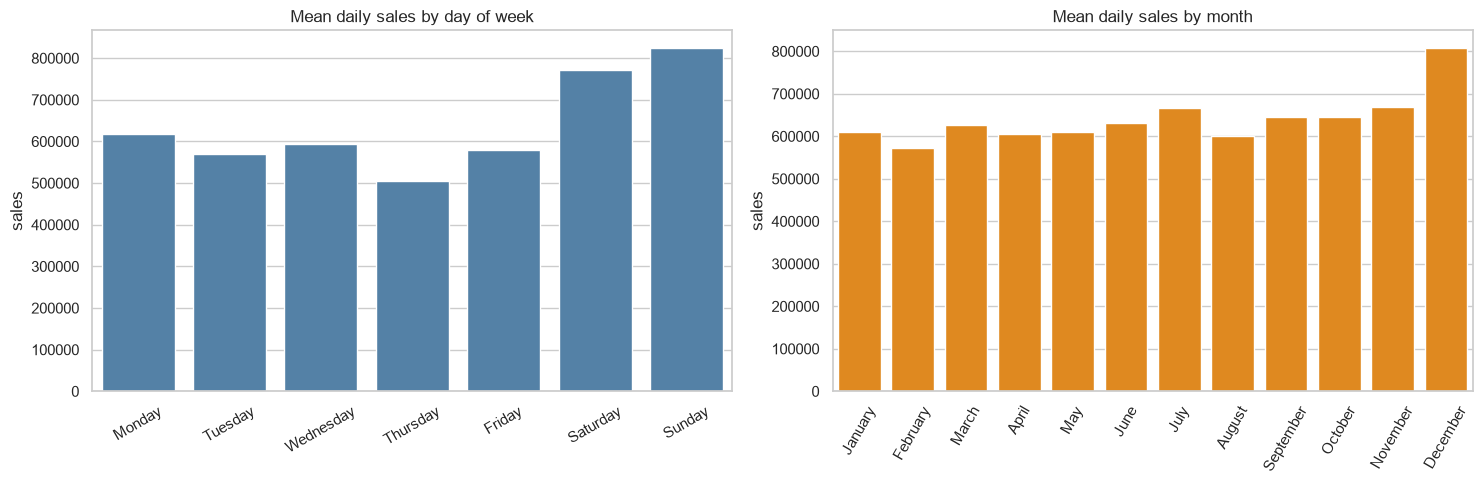

Highest day of week: Sunday (825,218)
Lowest day of week:  Thursday (505,269)
Highest month: December (808,565)


In [4]:
if train is not None:
    weekday = sales_by_weekday(train)
    month = sales_by_month(train)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(data=weekday, x="weekday_name", y="sales", ax=axes[0], color="steelblue")
    axes[0].set_title("Mean daily sales by day of week")
    axes[0].set_xlabel("")
    axes[0].tick_params(axis="x", rotation=30)

    sns.barplot(data=month, x="month_name", y="sales", ax=axes[1], color="darkorange")
    axes[1].set_title("Mean daily sales by month")
    axes[1].set_xlabel("")
    axes[1].tick_params(axis="x", rotation=60)

    fig.tight_layout()
    save_figure(fig, "week2_seasonality.png")
    plt.show()

    top_weekday = weekday.loc[weekday["sales"].idxmax()]
    low_weekday = weekday.loc[weekday["sales"].idxmin()]
    top_month = month.loc[month["sales"].idxmax()]
    print(f"Highest day of week: {top_weekday['weekday_name']} ({top_weekday['sales']:,.0f})")
    print(f"Lowest day of week:  {low_weekday['weekday_name']} ({low_weekday['sales']:,.0f})")
    print(f"Highest month: {top_month['month_name']} ({top_month['sales']:,.0f})")
else:
    print("Skipped: training data is not loaded.")

## 4. Sales across stores

Store totals and mean daily sales, joined with store metadata, plus a comparison by store type.

,store_nbr,total_sales,mean_daily_sales,city,state,type,cluster
0,44,62087553.25,1117.25,Quito,Pichincha,A,5
1,45,54498010.42,980.67,Quito,Pichincha,A,11
2,47,50948310.06,916.80,Quito,Pichincha,A,14
3,3,50481910.19,908.41,Quito,Pichincha,D,8
4,49,43420095.78,781.33,Quito,Pichincha,A,11
5,46,41896062.12,753.91,Quito,Pichincha,A,14
6,48,35933130.27,646.60,Quito,Pichincha,A,14
7,51,32911489.54,592.23,Guayaquil,Guayas,A,17
8,8,30494286.93,548.73,Quito,Pichincha,D,8
9,50,28653020.62,515.60,Ambato,Tungurahua,A,14


,store_nbr,total_sales,mean_daily_sales,city,state,type,cluster
49,35,7676679.42,138.14,Playas,Guayas,C,3
50,30,7382073.66,132.84,Guayaquil,Guayas,C,3
51,32,5951796.00,107.10,Guayaquil,Guayas,C,3
52,22,4090201.74,73.60,Puyo,Pastaza,C,7
53,52,2696169.73,48.52,Manta,Manabi,A,11


,mean,count
type,,
A,39227093.53,9
D,19504627.60,18
B,18157579.39,8
E,14955608.96,4
C,10962316.17,15


Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_store_sales.png


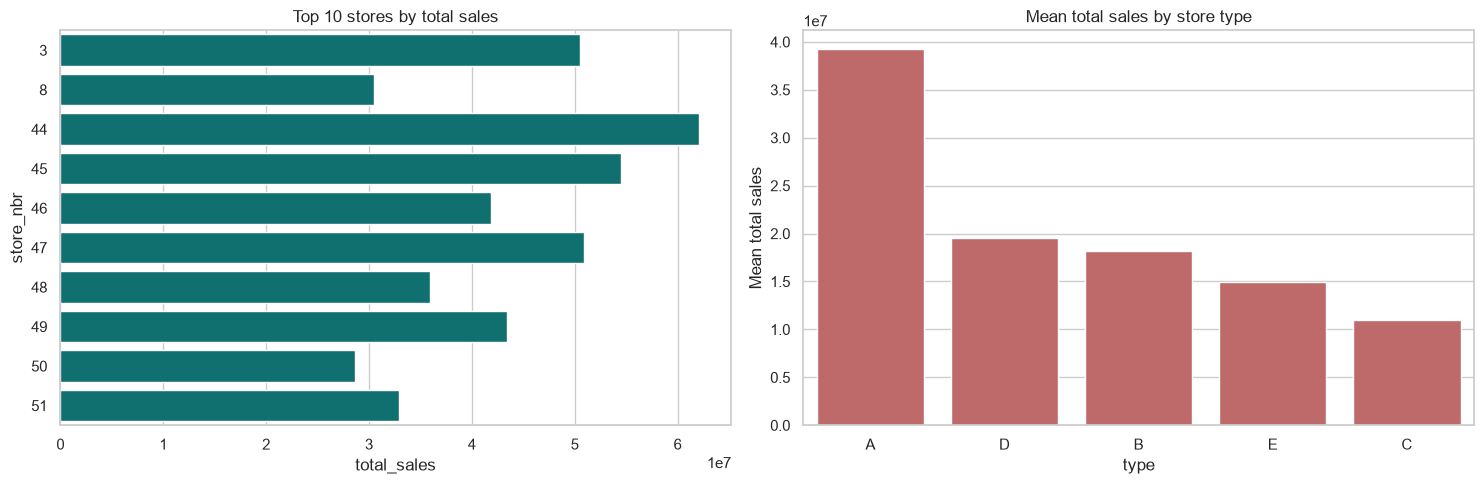

Highest store: 44 (Quito) 62,087,553
Lowest store:  52 (Manta) 2,696,170
Ratio best/worst: 23.0x


In [5]:
if train is not None:
    store_stats = sales_by_store(train, stores)
    display(store_stats.head(10).round(2))
    display(store_stats.tail(5).round(2))

    by_type = (
        store_stats.groupby("type")["total_sales"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
    )
    display(by_type.round(2))

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    top10 = store_stats.head(10)
    sns.barplot(data=top10, y="store_nbr", x="total_sales", ax=axes[0], color="teal", orient="h")
    axes[0].set_title("Top 10 stores by total sales")
    axes[0].set_ylabel("store_nbr")

    sns.barplot(data=by_type.reset_index(), x="type", y="mean", ax=axes[1], color="indianred")
    axes[1].set_title("Mean total sales by store type")
    axes[1].set_ylabel("Mean total sales")

    fig.tight_layout()
    save_figure(fig, "week2_store_sales.png")
    plt.show()

    best = store_stats.iloc[0]
    worst = store_stats.iloc[-1]
    print(f"Highest store: {int(best['store_nbr'])} ({best['city']}) {best['total_sales']:,.0f}")
    print(f"Lowest store:  {int(worst['store_nbr'])} ({worst['city']}) {worst['total_sales']:,.0f}")
    print(f"Ratio best/worst: {best['total_sales'] / worst['total_sales']:.1f}x")
else:
    print("Skipped: training data is not loaded.")

## 5. Sales across product families

,family,total_sales,mean_daily_sales,zero_sales_days
0,GROCERY I,3.434627e+08,3776.97,7332
1,BEVERAGES,2.169545e+08,2385.79,7331
2,PRODUCE,1.227047e+08,1349.35,25785
3,CLEANING,9.752129e+07,1072.42,7331
4,DAIRY,6.448771e+07,709.15,7331
5,BREAD/BAKERY,4.213395e+07,463.34,7330
6,POULTRY,3.187600e+07,350.53,7344
7,MEATS,3.108647e+07,341.85,7331
8,PERSONAL CARE,2.459205e+07,270.43,7334
9,DELI,2.411032e+07,265.14,7331


,family,total_sales,mean_daily_sales,zero_sales_days
28,MAGAZINES,266359.0,2.93,51414
29,HARDWARE,103470.0,1.14,43524
30,HOME APPLIANCES,41601.0,0.46,66854
31,BABY CARE,10051.0,0.11,85599
32,BOOKS,6438.0,0.07,88167


Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_family_sales.png


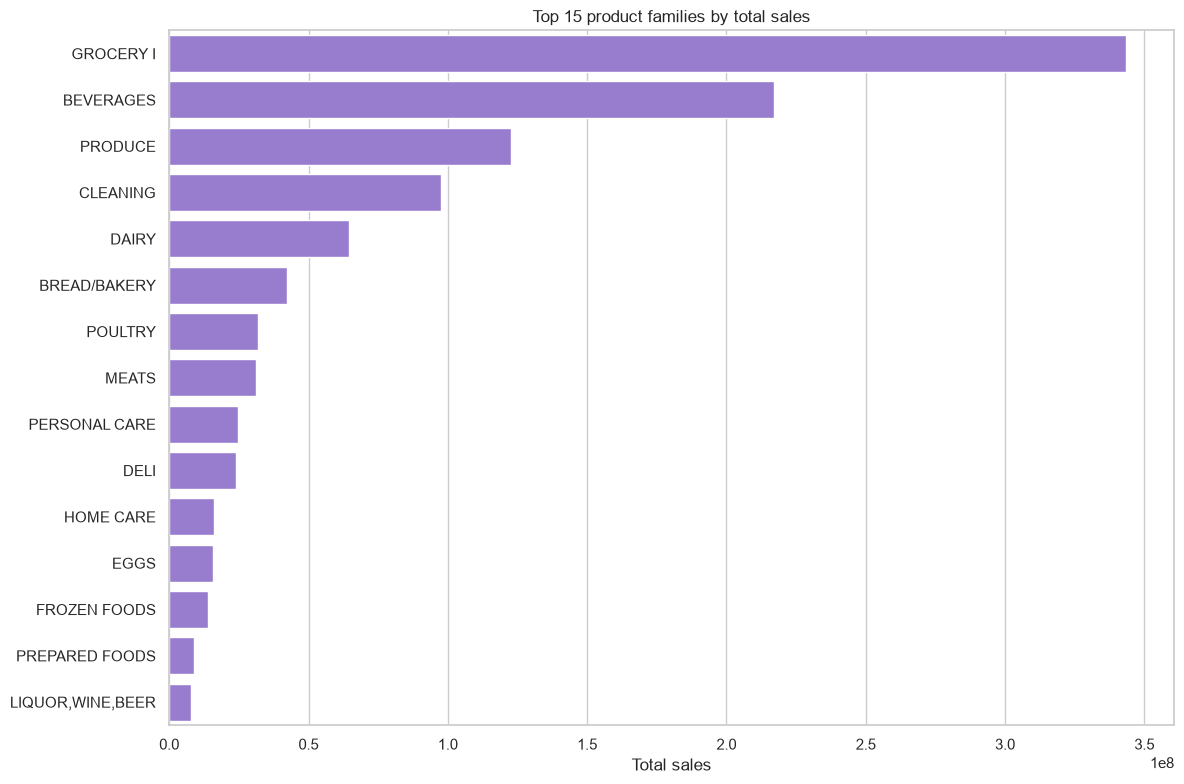

Number of families: 33
Top family: GROCERY I (343,462,735)
Bottom family: BOOKS (6,438)
Top 10 families share of total sales: 93.0%


In [6]:
if train is not None:
    family_stats = sales_by_family(train)
    display(family_stats.head(10).round(2))
    display(family_stats.tail(5).round(2))

    fig, ax = plt.subplots(figsize=(12, 8))
    top15 = family_stats.head(15)
    sns.barplot(data=top15, y="family", x="total_sales", ax=ax, color="mediumpurple")
    ax.set_title("Top 15 product families by total sales")
    ax.set_xlabel("Total sales")
    ax.set_ylabel("")
    fig.tight_layout()
    save_figure(fig, "week2_family_sales.png")
    plt.show()

    print(f"Number of families: {len(family_stats)}")
    print(f"Top family: {family_stats.iloc[0]['family']} ({family_stats.iloc[0]['total_sales']:,.0f})")
    print(f"Bottom family: {family_stats.iloc[-1]['family']} ({family_stats.iloc[-1]['total_sales']:,.0f})")
    share_top10 = family_stats.head(10)["total_sales"].sum() / family_stats["total_sales"].sum()
    print(f"Top 10 families share of total sales: {share_top10:.1%}")
else:
    print("Skipped: training data is not loaded.")

## 6. Promotions

Compare sales on promoted vs non-promoted rows. `onpromotion` counts items under promotion and is not a binary flag.

,value
threshold,1.000000
promoted_rows,611329.000000
promoted_share,0.203716
mean_sales_promoted,1137.693730
mean_sales_regular,158.246681
median_sales_promoted,373.000000
median_sales_regular,3.000000


,group,mean_sales,median_sales
0,Not promoted,158.246681,3.0
1,Promoted,1137.693730,373.0


Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_promotions.png


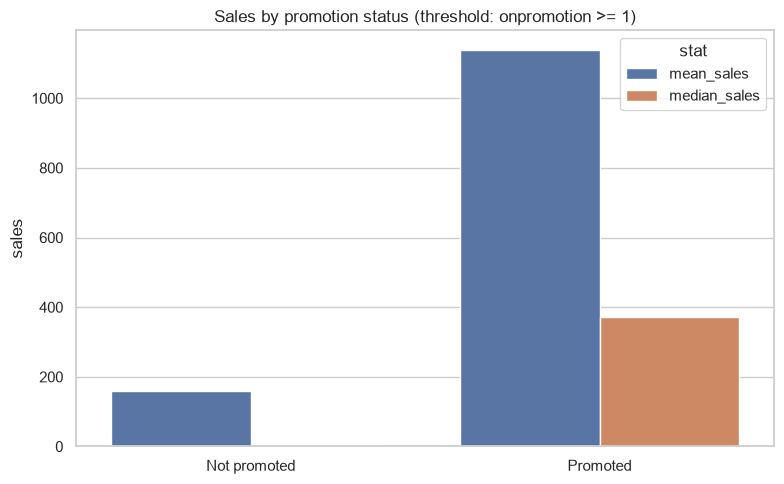

Promoted rows: 611,329 (20.4%)
Mean sales promoted vs not: 1,137.7 vs 158.2


In [7]:
if train is not None:
    summary = promotion_summary(train)
    display(pd.Series(summary, name="value").to_frame())

    comparison = pd.DataFrame(
        {
            "group": ["Not promoted", "Promoted"],
            "mean_sales": [summary["mean_sales_regular"], summary["mean_sales_promoted"]],
            "median_sales": [summary["median_sales_regular"], summary["median_sales_promoted"]],
        }
    )
    display(comparison)

    fig, ax = plt.subplots(figsize=(8, 5))
    long = comparison.melt(id_vars="group", var_name="stat", value_name="sales")
    sns.barplot(data=long, x="group", y="sales", hue="stat", ax=ax)
    ax.set_title("Sales by promotion status (threshold: onpromotion >= 1)")
    ax.set_xlabel("")
    fig.tight_layout()
    save_figure(fig, "week2_promotions.png")
    plt.show()

    print(f"Promoted rows: {summary['promoted_rows']:,} ({summary['promoted_share']:.1%})")
    print(f"Mean sales promoted vs not: {summary['mean_sales_promoted']:,.1f} vs {summary['mean_sales_regular']:,.1f}")
else:
    print("Skipped: training data is not loaded.")

## 7. Holidays and events

Compare average daily sales on national holidays vs other days.

,type,count
0,Holiday,221
1,Event,56
2,Additional,51
3,Transfer,12
4,Bridge,5
5,Work Day,5


,mean,count
is_national_holiday,,
False,627918.11,1548
True,747262.61,136


Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_holidays.png


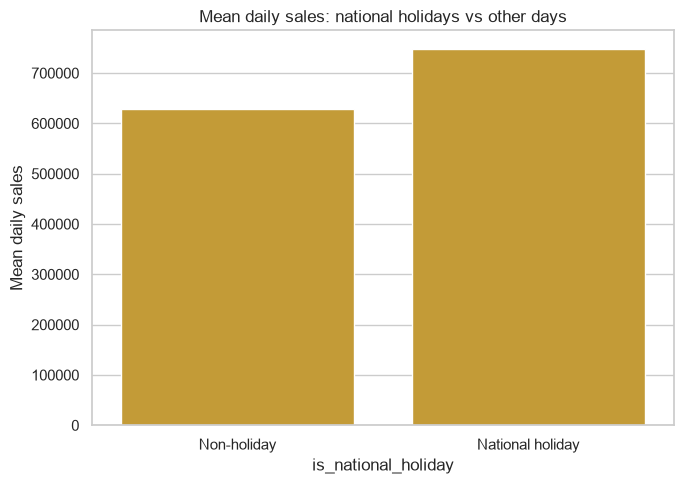

National holiday days: 136
Mean sales non-holiday: 627,918
Mean sales holiday:     747,263


In [8]:
if train is not None:
    display(holidays_by_type(holidays))

    national = holidays[(holidays["locale"] == "National") & (~holidays["transferred"])]
    national_dates = set(national["date"].dt.normalize())

    daily = daily_sales(train)
    daily["is_national_holiday"] = daily["date"].isin(national_dates)
    holiday_stats = daily.groupby("is_national_holiday")["sales"].agg(["mean", "count"])
    display(holiday_stats.round(2))

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.barplot(
        data=holiday_stats.reset_index(),
        x="is_national_holiday",
        y="mean",
        ax=ax,
        color="goldenrod",
    )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-holiday", "National holiday"])
    ax.set_title("Mean daily sales: national holidays vs other days")
    ax.set_ylabel("Mean daily sales")
    fig.tight_layout()
    save_figure(fig, "week2_holidays.png")
    plt.show()

    print(f"National holiday days: {int(holiday_stats.loc[True, 'count'])}")
    print(f"Mean sales non-holiday: {holiday_stats.loc[False, 'mean']:,.0f}")
    print(f"Mean sales holiday:     {holiday_stats.loc[True, 'mean']:,.0f}")
else:
    print("Skipped: training data is not loaded.")

## 8. Transactions

Transaction counts cover a shorter window than train (through 2017-08-15). Join on shared dates only.

Shared days: 1682
Correlation (daily total sales vs daily total transactions): 0.677


Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_transactions.png


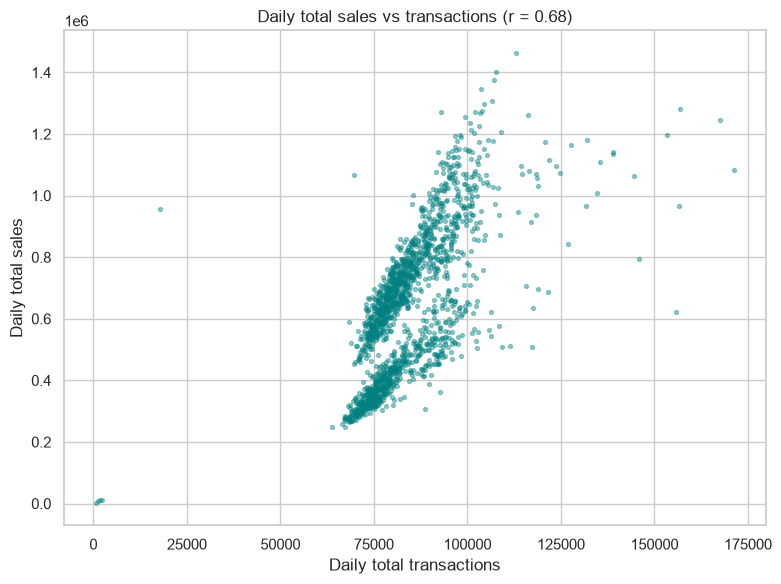

In [9]:
if train is not None:
    daily = daily_sales(train)
    txn_daily = transactions.groupby("date", as_index=False)["transactions"].sum()
    merged = daily.merge(txn_daily, on="date", how="inner")

    corr = merged["sales"].corr(merged["transactions"])
    print(f"Shared days: {len(merged)}")
    print(f"Correlation (daily total sales vs daily total transactions): {corr:.3f}")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(merged["transactions"], merged["sales"], s=8, alpha=0.4, color="teal")
    ax.set_title(f"Daily total sales vs transactions (r = {corr:.2f})")
    ax.set_xlabel("Daily total transactions")
    ax.set_ylabel("Daily total sales")
    fig.tight_layout()
    save_figure(fig, "week2_transactions.png")
    plt.show()
else:
    print("Skipped: training data is not loaded.")

## 9. Oil prices

Oil has a daily series with gaps; the join uses a forward-filled price and 43 original missing values remain in the raw file.

Raw oil missing values: 43 of 1218
Correlation (daily total sales vs forward-filled oil price): -0.627


Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week2_oil_vs_sales.png


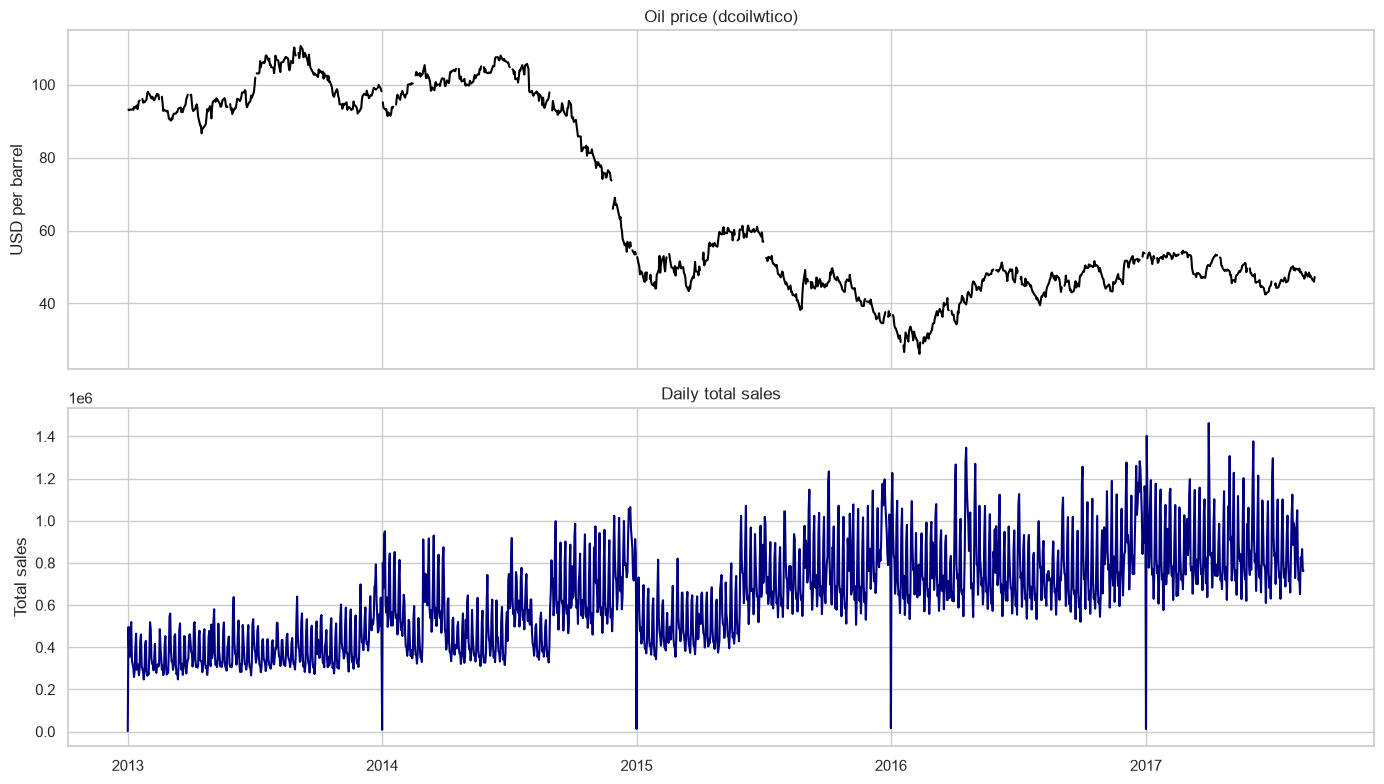

In [10]:
if train is not None:
    oil_series = oil_price_trend(oil)
    merged = merge_oil_with_sales(train, oil)
    corr = merged["sales"].corr(merged["dcoilwtico"])
    print(f"Raw oil missing values: {int(oil['dcoilwtico'].isna().sum())} of {len(oil)}")
    print(f"Correlation (daily total sales vs forward-filled oil price): {corr:.3f}")

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(oil_series["date"], oil_series["dcoilwtico"], color="black")
    axes[0].set_title("Oil price (dcoilwtico)")
    axes[0].set_ylabel("USD per barrel")

    axes[1].plot(merged["date"], merged["sales"], color="navy")
    axes[1].set_title("Daily total sales")
    axes[1].set_ylabel("Total sales")

    fig.tight_layout()
    save_figure(fig, "week2_oil_vs_sales.png")
    plt.show()
else:
    print("Skipped: training data is not loaded.")

## 10. Data quality

Summary of missing values across datasets, plus a check that every store is present in `stores.csv`.

In [11]:
if train is not None:
    report = missing_value_report(datasets)
    if report.empty:
        print("No missing values in any loaded dataset.")
    else:
        display(report.round(4))

    print(f"Zero-sales share in train: {(train['sales'] == 0).mean():.1%}")
    print(f"All train stores present in stores.csv: {set(train['store_nbr']) == set(stores['store_nbr'])}")
    print(f"Stores with an oil price on every train date: {merged['dcoilwtico'].notna().all()}")
else:
    print("Skipped: training data is not loaded.")

,dataset,column,missing_count,missing_share
0,oil,dcoilwtico,43,0.0353


Zero-sales share in train: 31.3%
All train stores present in stores.csv: True
Stores with an oil price on every train date: True


## 11. Findings

### Sales trend
- Total sales grow strongly over the period: about 140.4M in 2013 to 288.7M in 2016. 2017 is partial (through 2017-08-15), so it is lower in aggregate but the monthly level is the highest of the series.
- The strongest single month is December 2016 (about 29.6M); the weakest is February 2013 (about 9.7M).

### Seasonality
- Day of week matters: Sunday and Saturday have the highest mean daily sales (about 825K and 772K), while Thursday is the lowest (about 505K).
- Month matters: December is clearly the peak (about 809K mean daily), consistent with holiday shopping; February is the weakest (about 572K).

### Stores
- Sales are very concentrated: store 44 (Quito, type A) leads with about 62.1M, while store 52 (Manta, type A) is lowest at about 2.7M — roughly a 23x gap.
- Store type A has the highest mean total sales; type C the lowest. Larger-format stores dominate.

### Product families
- GROCERY I is by far the largest family (about 343M), followed by BEVERAGES (about 217M) and PRODUCE (about 123M).
- The top 10 families account for the large majority of sales, while families like BOOKS, BABY CARE, and HOME APPLIANCES contribute very little and have many zero-sales days.

### Promotions
- About 20.4% of rows have `onpromotion >= 1`.
- Promoted rows have a much higher mean sales (about 1,138 vs 158) and median sales (373 vs 3). Promotion is a strong signal, but it is also likely correlated with high-volume families, so it is not proof of a causal lift.

### Holidays
- There are 221 holiday-type entries. Mean daily sales on national holidays (about 747K) exceed non-holiday days (about 628K).
- Many holiday rows are local/regional, so national-holiday analysis understates the coverage.

### Transactions
- Daily total transactions correlate positively with daily total sales (r about 0.68), making transactions a useful demand signal.

### Oil
- Daily sales correlate negatively with the oil price (r about -0.63). Because both series trend over time, this is likely a spurious/confounded relationship rather than a direct driver.

### Data-quality issues
- `oil.csv` has 43 missing values in `dcoilwtico`; forward-fill or interpolation will be needed.
- About 31.3% of train rows have zero sales. This zero-inflation matters for both evaluation metrics and modeling.
- `transactions.csv` ends on 2017-08-15, so it does not cover the full test window.
- `train.csv` ends 2017-08-15 while `holidays_events.csv` extends to 2017-12-26; future holidays must come from the holidays file, not train.
- No duplicate keys or missing required values were found in train, and every train store appears in `stores.csv`.

## Next steps

Week 3 uses these findings to build chronological splits and leakage-safe features (calendar, promotions, and careful lag/rolling features), then establishes a simple baseline. No model is trained in this notebook.